# COEN872 – Pothole / Road-Defect Detection (YOLOv8n)
Baseline training, evaluation and export for the edge-AI trade-off study.

**Before running:** Runtime → Change runtime type → **T4 GPU**.
Add your Roboflow key under the 🔑 **Secrets** tab as `ROBOFLOW_API_KEY` and enable notebook access. Never paste the key into a cell.

In [ ]:
!nvidia-smi

Tue Sep 22 20:54:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q roboflow ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 50.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 121.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 9.4 MB/s eta 0:00:00


## 1. Mount Drive (Colab sessions reset, so save everything here)

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/COEN872_pothole'
os.makedirs(OUT, exist_ok=True)
print('Saving to', OUT)

Mounted at /content/drive
Saving to /content/drive/MyDrive/COEN872_pothole


## 2. Download the dataset

In [ ]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
project = rf.workspace('abdulhamid-musa').project('indiardd2022-vh6fa')
dataset = project.version(2).download('yolov8')
print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to IndiaRDD2022-2 in yolov8:: 100%|██████████| 6808/6808 [00:00<00:00, 8924.55it/s] 


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
/content/IndiaRDD2022-2


In [ ]:
import glob
print(open(f'{dataset.location}/data.yaml').read())
for s in ['train', 'valid', 'test']:
    n = len(glob.glob(f'{dataset.location}/{s}/images/*'))
    print(s, n, 'images')

names:
- '0'
nc: 1
roboflow:
  license: CC BY 4.0
  project: indiardd2022-vh6fa
  url: https://app.roboflow.com/abdulhamid-musa/indiardd2022-vh6fa/2
  version: 2
  workspace: abdulhamid-musa
test: ../test/images
train: ../train/images
val: ../valid/images

train 3140 images
valid 131 images
test 131 images


## 3. Train the FP32 baseline (YOLOv8n)
Check that augmentation was applied to the **train split only** in Roboflow, otherwise the metrics will be inflated.

In [ ]:
from ultralytics import YOLO

DATA = f'{dataset.location}/data.yaml'
model = YOLO('yolov8n.pt')          # COCO-pretrained
model.train(
    data=DATA, epochs=50, imgsz=640, batch=16,
    patience=15, seed=0,
    project=OUT, name='yolov8n_baseline', exist_ok=True,
)

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IndiaRDD2022-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=64, nms=None, opset=No

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c86502ca350>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## 4. Evaluate on the held-out public test split

In [ ]:
BEST = f'{OUT}/yolov8n_baseline/weights/best.pt'
best = YOLO(BEST)
m = best.val(data=DATA, split='test', imgsz=640)

p, r = m.box.mp, m.box.mr
f1 = 2 * p * r / (p + r + 1e-9)
print(f'Precision {p:.3f} | Recall {r:.3f} | F1 {f1:.3f}')
print(f'mAP@0.5 {m.box.map50:.3f} | mAP@0.5:0.95 {m.box.map:.3f}')
for name, ap in zip(m.names.values(), m.box.ap50):
    print(f'  {name}: AP50 = {ap:.3f}')

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 848.2±397.6 MB/s, size: 27.4 KB)
val: Scanning /content/IndiaRDD2022-2/test/labels... 131 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 131/131 2.1Kit/s 0.1s
val: New cache created: /content/IndiaRDD2022-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.0it/s 3.0s
                   all        131        199       0.45      0.281       0.29        0.1
Speed: 4.5ms preprocess, 6.1ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/runs/detect/val
Precision 0.450 | Recall 0.281 | F1 0.346
mAP@0.5 0.290 | mAP@0.5:0.95 0.100
  0: AP50 = 0.290


## 5. Local Nigerian test set (your secondary finding)
Annotate your 30–50 Zaria/Kano images in Roboflow (same classes as RDD), export as YOLOv8, and download them here. **These must never appear in training.**

In [ ]:
# Fill in once your local Roboflow project exists, then run this cell.
LOCAL_WORKSPACE = 'abdulhamid-musa'
LOCAL_PROJECT   = 'REPLACE_WITH_LOCAL_PROJECT_ID'
LOCAL_VERSION   = 1

if LOCAL_PROJECT != 'REPLACE_WITH_LOCAL_PROJECT_ID':
    local = rf.workspace(LOCAL_WORKSPACE).project(LOCAL_PROJECT).version(LOCAL_VERSION).download('yolov8')
    ml = best.val(data=f'{local.location}/data.yaml', split='test', imgsz=640)
    p, r = ml.box.mp, ml.box.mr
    print(f'LOCAL  P {p:.3f} R {r:.3f} F1 {2*p*r/(p+r+1e-9):.3f} '
          f'mAP50 {ml.box.map50:.3f} mAP50-95 {ml.box.map:.3f}')
else:
    print('Local dataset not set yet, skipping.')

Local dataset not set yet, skipping.


## 6. Export for the browser (TensorFlow.js)
Exports can be fragile across library versions, so each is wrapped in try/except. If one fails, read the error and re-run that cell alone.

In [ ]:
try:
    best.export(format='tfjs')                # FP32
except Exception as e:
    print('tfjs FP32 export failed:', e)

try:
    best.export(format='tfjs', int8=True)     # quantized
except Exception as e:
    print('tfjs INT8 export failed:', e)

# Optional extra column: true INT8 via TFLite
try:
    best.export(format='tflite', int8=True, data=DATA)
except Exception as e:
    print('tflite INT8 export failed:', e)

WARNING ⚠️ format='tfjs' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.0 MB)
requirements: Ultralytics requirements ['litert-torch>=0.9.0', 'ai-edge-litert>=2.1.4'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 86 packages in 612ms
Prepared 15 packages in 1.84s
Uninstalled 3 packages in 31ms
Installed 15 packages in 42ms
 + ai-edge-litert==2.2.0
 +

invalid escape sequence '\.'



LiteRT: starting export with litert_torch 0.9.4...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

...

(00:00) [START] Write Model to /content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite

(00:00) [ DONE] Write Model to /content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite 
(+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


Applying Transformations to tensors:: 100%|██████████| 412/412 [00:00<00:00, 20717.83it/s]


Model name: /content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite
Original model size: 11.69 MiB
Quantized model size: 3.17 MiB
Quantization Ratio: 0.27 (3.7x smaller)
Total time: 171.57 ms
LiteRT: export success ✅ 115.6s, saved as '/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite' (3.2 MB)

Export complete (116.2s)
Results saved to /content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite
Predict:         yolo predict task=detect model=/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite imgsz=640 data=/content/IndiaRDD2022-2/data.yaml  
Visualize:       https://netron.app


In [ ]:
import pathlib, pandas as pd

def size_mb(path):
    path = pathlib.Path(path)
    if path.is_file():
        return path.stat().st_size / 1e6
    return sum(f.stat().st_size for f in path.rglob('*') if f.is_file()) / 1e6

wdir = pathlib.Path(BEST).parent
rows = [('PyTorch best.pt', size_mb(BEST))]
for p_ in sorted(wdir.iterdir()):
    if p_.name.endswith('_web_model') or p_.suffix == '.tflite' or p_.name.endswith('_saved_model'):
        rows.append((p_.name, size_mb(p_)))
pd.DataFrame(rows, columns=['artifact', 'size_MB'])

,artifact,size_MB
0,PyTorch best.pt,6.250666
1,best.tflite,12.255926
2,best_int8.tflite,3.328492


## 7. Rough latency (Colab only)
This measures Colab hardware, **not** a phone. Your real latency numbers must come from the browser demo on the actual device(s). Use this only as a sanity check.

In [ ]:
import time, glob, numpy as np

imgs = sorted(glob.glob(f'{dataset.location}/test/images/*'))[:50]
def bench(device):
    best.predict(imgs[0], device=device, imgsz=640, verbose=False)   # warm-up
    ts = []
    for f in imgs:
        t = time.perf_counter()
        best.predict(f, device=device, imgsz=640, verbose=False)
        ts.append((time.perf_counter() - t) * 1000)
    return np.mean(ts), np.percentile(ts, 95)

for dev in ['cpu', 0]:
    mean, p95 = bench(dev)
    print(f'device={dev}: mean {mean:.1f} ms | p95 {p95:.1f} ms')

device=cpu: mean 118.9 ms | p95 128.2 ms
device=0: mean 12.8 ms | p95 16.1 ms


In [ ]:
from ultralytics import YOLO
import os

# Check the local data is still in this session
for p in ['/content/local_test/test/images', '/content/local_train/train/images', '/content/local_test.yaml']:
    print(p, 'OK' if os.path.exists(p) else 'MISSING')

W = f'{OUT}/yolov8n_baseline/weights'
m = YOLO(f'{W}/best.pt').val(data='/content/local_test.yaml', split='test', imgsz=640, verbose=False)
p, r = m.box.mp, m.box.mr
print(f'PUBLIC MODEL on LOCAL test | P {p:.3f} R {r:.3f} F1 {2*p*r/(p+r+1e-9):.3f} '
      f'mAP50 {m.box.map50:.3f} mAP50-95 {m.box.map:.3f}')

/content/local_test/test/images OK
/content/local_train/train/images OK
/content/local_test.yaml OK
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1241.0±577.1 MB/s, size: 78.1 KB)
val: Scanning /content/local_test/test/labels... 50 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 2.2Kit/s 0.0s
val: New cache created: /content/local_test/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0it/s 2.0s
                   all         50        161     0.0773      0.134     0.0347    0.00888
Speed: 8.3ms preprocess, 9.5ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to /content/runs/detect/val
PUBLIC MODEL on LOCAL test | P 0.077 R 0.134 F1 0.098 mAP50 0.035 mAP50-95 0.009


In [ ]:
from ultralytics import YOLO
W = f'{OUT}/yolov8n_baseline/weights'
ft = YOLO(f'{W}/best.pt')
ft.train(data='/content/local_train/data.yaml', epochs=50, imgsz=640, batch=16,
         patience=15, seed=0, project=OUT, name='yolov8n_local_ft', exist_ok=True)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/local_train/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x796d88335a90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
from ultralytics import YOLO
import os

F = f'{OUT}/yolov8n_local_ft/weights'
print('fine-tuned weights found:', os.path.exists(f'{F}/best.pt'))

m = YOLO(f'{F}/best.pt').val(data='/content/local_test.yaml', split='test', imgsz=640, verbose=False)
p, r = m.box.mp, m.box.mr
print(f'FINE-TUNED on LOCAL test | P {p:.3f} R {r:.3f} F1 {2*p*r/(p+r+1e-9):.3f} '
      f'mAP50 {m.box.map50:.3f} mAP50-95 {m.box.map:.3f}')

fine-tuned weights found: True
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1942.1±653.4 MB/s, size: 84.6 KB)
val: Scanning /content/local_test/test/labels.cache... 50 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 21.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.1it/s 1.9s
                   all         50        161        0.3      0.354      0.211     0.0843
Speed: 6.4ms preprocess, 5.5ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val-2
FINE-TUNED on LOCAL test | P 0.300 R 0.354 F1 0.325 mAP50 0.211 mAP50-95 0.084


boxes: 4645
median box w, h: 0.148 0.219
aspect median: 1.59 | 90th pct: 2.78
share aspect > 3 (crack-like): 0.073


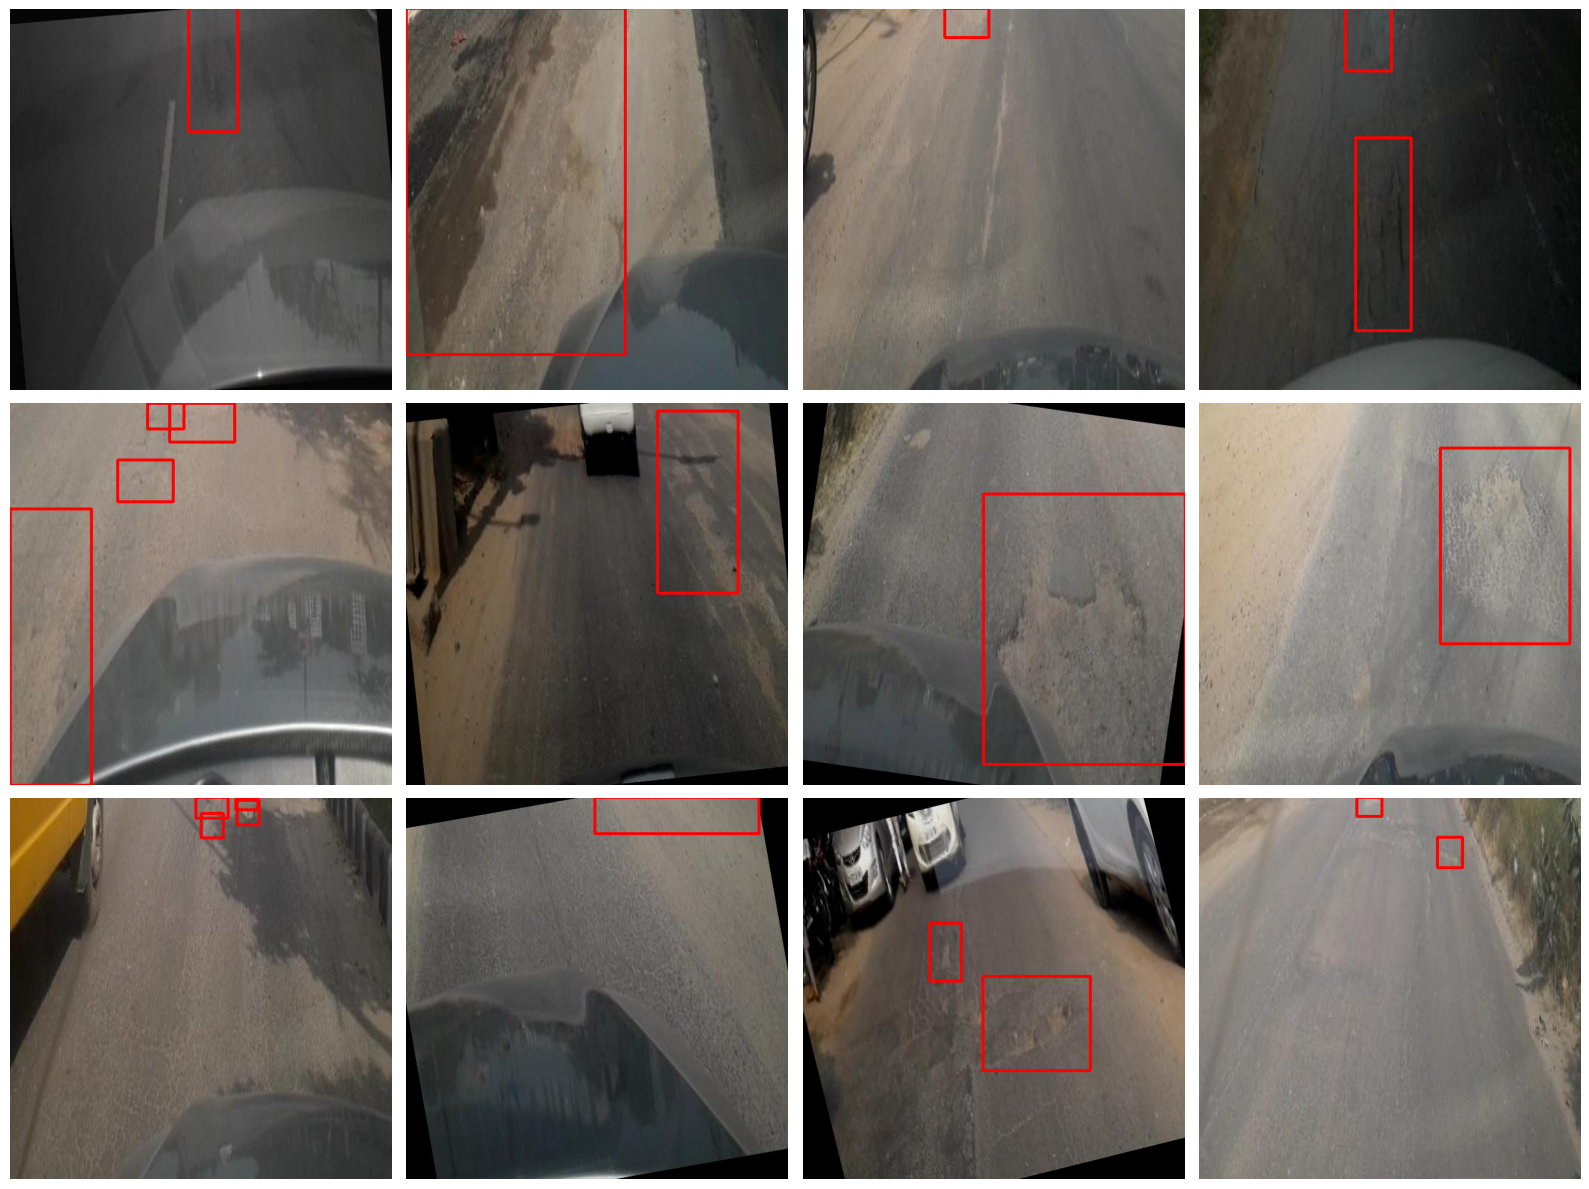

In [ ]:
import glob, os, random, numpy as np, cv2
import matplotlib.pyplot as plt

root = '/content/IndiaRDD2022-2'

ars, ws, hs = [], [], []
for f in glob.glob(f'{root}/train/labels/*.txt'):
    for line in open(f):
        parts = line.split()
        if len(parts) < 5: continue
        w, h = float(parts[3]), float(parts[4])
        ws.append(w); hs.append(h)
        ars.append(max(w, h) / max(min(w, h), 1e-6))
ars = np.array(ars)
print('boxes:', len(ars))
print('median box w, h:', round(np.median(ws), 3), round(np.median(hs), 3))
print('aspect median:', round(np.median(ars), 2), '| 90th pct:', round(np.percentile(ars, 90), 2))
print('share aspect > 3 (crack-like):', round((ars > 3).mean(), 3))

random.seed(0)
imgs = random.sample(glob.glob(f'{root}/train/images/*'), 12)
fig, axs = plt.subplots(3, 4, figsize=(16, 12))
for ax, p in zip(axs.ravel(), imgs):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    H, W = im.shape[:2]
    lf = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    if os.path.exists(lf):
        for line in open(lf):
            q = line.split()
            if len(q) < 5: continue
            x, y, w, h = map(float, q[1:5])
            cv2.rectangle(im, (int((x-w/2)*W), int((y-h/2)*H)),
                          (int((x+w/2)*W), int((y+h/2)*H)), (255, 0, 0), 3)
    ax.imshow(im); ax.axis('off')
plt.tight_layout(); plt.show()

## 8. Results are already in Drive
Weights, `results.csv`, confusion matrix and PR curves are in `COEN872_pothole/yolov8n_baseline/`.
Download the `*_web_model` folders and use them in your TensorFlow.js page.

**Next:** repeat section 3 with `yolov8s.pt` (optional third configuration), and later fine-tune on your local training images.

In [ ]:
# Section 10, step 1: build a calibration yaml for INT8 export.
# The old INT8 file was calibrated on 4 COCO images. This points calibration at the
# public training images (val = train/images), uses the pothole name, and prints the
# Ultralytics version for the report. Expected: version, then "3140 calibration candidates".
import yaml, os, glob, ultralytics
print('Ultralytics', ultralytics.__version__)

root = '/content/IndiaRDD2022-2'
cal = {'path': root, 'train': 'train/images', 'val': 'train/images', 'names': ['pothole']}
yaml.safe_dump(cal, open('/content/calib_public.yaml', 'w'))
print(len(glob.glob(f'{root}/train/images/*')), 'calibration candidates')

Ultralytics 8.4.174
3140 calibration candidates


In [ ]:
# Section 10, step 2: export the public model as FP32 (config A) and INT8 (config B).
# Uses LiteRT because tfjs was replaced in Ultralytics 8.4.83. INT8 calibrates on about
# 600 real road images (fraction=0.2). This overwrites the old best_int8.tflite.
# Check the output for "collecting INT8 calibration images from data=/content/calib_public.yaml"
# with several hundred images. If 'fraction' errors, delete that argument and rerun.
from ultralytics import YOLO
OUTW = f'{OUT}/yolov8n_baseline/weights'
m = YOLO(f'{OUTW}/best.pt')
m.export(format='litert')
m.export(format='litert', quantize=8, data='/content/calib_public.yaml', fraction=0.2)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.0 MB)
requirements: Ultralytics requirements ['litert-torch>=0.9.0', 'ai-edge-litert>=2.1.4'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 86 packages in 594ms
Prepared 16 packages in 6.00s
Uninstalled 4 packages in 36ms
Installed 16 packages in 36ms
 + ai-edge-litert==2.2.0
 + ai-edge-quantizer==0.9.0
 - anyio==4.15.1
 + anyio==4.14.2
 + backports-strenum==1.3.1
 + fire==0.7.1
 - immutabledict==4.3.1
 + immutabledict==4.2.1
 + jaxtyping==0.3.11
 + litert-converter==0.4.0


invalid escape sequence '\.'



LiteRT: starting export with litert_torch 0.9.4...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

...

(00:00) [ DONE] Write Model to /content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite 
(+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


Applying Transformations to tensors:: 100%|██████████| 412/412 [00:00<00:00, 16135.10it/s]


Model name: /content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite
Original model size: 11.69 MiB
Quantized model size: 3.17 MiB
Quantization Ratio: 0.27 (3.7x smaller)
Total time: 185.93 ms
LiteRT: export success ✅ 466.2s, saved as '/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite' (3.2 MB)

Export complete (466.5s)
Results saved to /content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite
Predict:         yolo predict task=detect model=/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite imgsz=640 data=/content/IndiaRDD2022-2/data.yaml  
Visualize:       https://netron.app


'/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best_int8.tflite'

In [ ]:
# Section 10, step 3: evaluate configs A and B on the public test split and the 50 local images.
# A should be close to the PyTorch results (about 0.29 public, 0.035 local mAP50).
# B should be within a few points of A. If local_test.yaml is missing, Colab was reset.
import os, pandas as pd
from ultralytics import YOLO

rows = []
for cfg, f in [('A public FP32', 'best.tflite'), ('B public INT8', 'best_int8.tflite')]:
    for dname, y in [('public test', f'{root}/data.yaml'), ('local test', '/content/local_test.yaml')]:
        if not os.path.exists(y):
            print('missing', y); continue
        r = YOLO(f'{OUTW}/{f}').val(data=y, split='test', imgsz=640, verbose=False)
        p, rc = r.box.mp, r.box.mr
        rows.append((cfg, dname, round(p, 3), round(rc, 3), round(2*p*rc/(p+rc+1e-9), 3),
                     round(r.box.map50, 3), round(r.box.map, 3)))
pd.DataFrame(rows, columns=['config', 'test set', 'P', 'R', 'F1', 'mAP50', 'mAP50-95'])

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best.tflite for LiteRT inference...
Setting batch=1 input of shape (1, 3, 640, 640)
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 28.9±46.2 MB/s, size: 25.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/IndiaRDD2022-2/test/labels... 131 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 131/131 636.0it/s 0.2s
val: New cache created: /content/IndiaRDD2022-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 131/131 5.9it/s 22.0s
                   all        131        199      0.472      0.314      0.269     0.0987
Speed: 1.7ms preprocess, 155.3ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /conte

,config,test set,P,R,F1,mAP50,mAP50-95
0,A public FP32,public test,0.472,0.314,0.377,0.269,0.099
1,A public FP32,local test,0.082,0.131,0.101,0.043,0.011
2,B public INT8,public test,0.349,0.347,0.348,0.250,0.086
3,B public INT8,local test,0.091,0.124,0.105,0.063,0.019


In [ ]:
# Section 10, step 4: export and evaluate the fine-tuned model (configs C and D).
# INT8 calibrates on the 359 local training images (this model's own training data).
# Both configs are tested on the public test split and the 50 local images.
# The table is saved to Drive as a CSV, because Colab files are lost on reset.
import yaml, os, pandas as pd
from ultralytics import YOLO

FW = f'{OUT}/yolov8n_local_ft/weights'
cal = {'path': '/content/local_train', 'train': 'train/images', 'val': 'train/images', 'names': ['pothole']}
yaml.safe_dump(cal, open('/content/calib_local.yaml', 'w'))

m = YOLO(f'{FW}/best.pt')
m.export(format='litert')                                          # C: FP32
m.export(format='litert', quantize=8, data='/content/calib_local.yaml')   # D: INT8

rows = []
for cfg, f in [('C ft FP32', 'best.tflite'), ('D ft INT8', 'best_int8.tflite')]:
    for dname, y in [('public test', f'{root}/data.yaml'), ('local test', '/content/local_test.yaml')]:
        r = YOLO(f'{FW}/{f}').val(data=y, split='test', imgsz=640, verbose=False)
        p, rc = r.box.mp, r.box.mr
        rows.append((cfg, dname, round(p, 3), round(rc, 3), round(2*p*rc/(p+rc+1e-9), 3),
                     round(r.box.map50, 3), round(r.box.map, 3)))
res = pd.DataFrame(rows, columns=['config', 'test set', 'P', 'R', 'F1', 'mAP50', 'mAP50-95'])
res.to_csv(f'{OUT}/results_C_D.csv', index=False)
res

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/COEN872_pothole/yolov8n_local_ft/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.0 MB)

LiteRT: starting export with litert_torch 0.9.4...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


...

(00:00) [ DONE] Write Model to /content/drive/MyDrive/COEN872_pothole/yolov8n_local_ft/weights/best_int8.tflite 
(+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


Applying Transformations to tensors:: 100%|██████████| 412/412 [00:00<00:00, 12535.75it/s]


Model name: /content/drive/MyDrive/COEN872_pothole/yolov8n_local_ft/weights/best_int8.tflite
Original model size: 11.69 MiB
Quantized model size: 3.17 MiB
Quantization Ratio: 0.27 (3.7x smaller)
Total time: 283.58 ms
LiteRT: export success ✅ 219.5s, saved as '/content/drive/MyDrive/COEN872_pothole/yolov8n_local_ft/weights/best_int8.tflite' (3.2 MB)

Export complete (219.7s)
Results saved to /content/drive/MyDrive/COEN872_pothole/yolov8n_local_ft/weights/best_int8.tflite
Predict:         yolo predict task=detect model=/content/drive/MyDrive/COEN872_pothole/yolov8n_local_ft/weights/best_int8.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/COEN872_pothole/yolov8n_local_ft/weights/best_int8.tflite imgsz=640 data=/content/local_train/data.yaml  
Visualize:       https://netron.app
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/drive/MyDrive/COEN872_pothole/yolov8n_local_ft/weights/best.tflite for Lite

,config,test set,P,R,F1,mAP50,mAP50-95
0,C ft FP32,public test,0.078,0.080,0.079,0.029,0.008
1,C ft FP32,local test,0.335,0.323,0.329,0.230,0.096
2,D ft INT8,public test,0.078,0.090,0.084,0.026,0.006
3,D ft INT8,local test,0.281,0.286,0.283,0.215,0.090


In [ ]:
# Section 10, step 5: check the fine-tuned PyTorch model on the public test split.
# Confirms the public-accuracy drop is real forgetting and not a LiteRT export problem.
# Also saves the A and B results to Drive (their table variable was overwritten).
import pandas as pd
from ultralytics import YOLO

r = YOLO(f'{OUT}/yolov8n_local_ft/weights/best.pt').val(
    data=f'{root}/data.yaml', split='test', imgsz=640, verbose=False)
p, rc = r.box.mp, r.box.mr
print(f'FT PyTorch on PUBLIC test | P {p:.3f} R {rc:.3f} F1 {2*p*rc/(p+rc+1e-9):.3f} '
      f'mAP50 {r.box.map50:.3f} mAP50-95 {r.box.map:.3f}')

ab = pd.DataFrame([
    ('A public FP32', 'public test', 0.472, 0.314, 0.377, 0.269, 0.099),
    ('A public FP32', 'local test',  0.082, 0.131, 0.101, 0.043, 0.011),
    ('B public INT8', 'public test', 0.349, 0.347, 0.348, 0.250, 0.086),
    ('B public INT8', 'local test',  0.091, 0.124, 0.105, 0.063, 0.019)],
    columns=['config', 'test set', 'P', 'R', 'F1', 'mAP50', 'mAP50-95'])
ab.to_csv(f'{OUT}/results_A_B.csv', index=False)
print('saved results_A_B.csv')

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1159.2±315.2 MB/s, size: 30.0 KB)
val: Scanning /content/IndiaRDD2022-2/test/labels.cache... 131 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 131/131 36.6Mit/s 0.0s


os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.9it/s 4.7s
                   all        131        199      0.102     0.0905     0.0422     0.0111
Speed: 7.0ms preprocess, 7.0ms inference, 0.0ms loss, 4.8ms postprocess per image
Results saved to /content/runs/detect/val-11
FT PyTorch on PUBLIC test | P 0.102 R 0.090 F1 0.096 mAP50 0.042 mAP50-95 0.011
saved results_A_B.csv


In [ ]:
# Section 10, step 7 (alternative to mixed training): gentle fine-tuning on local data only.
# Same baseline start and seed, but backbone frozen (freeze=10), low learning rate,
# SGD (so lr0 is respected) and fewer epochs, to reduce forgetting of the public data.
# Saves to a new folder, so earlier models are untouched. Tested on both test sets in PyTorch.
import pandas as pd
from ultralytics import YOLO

g = YOLO(f'{OUT}/yolov8n_baseline/weights/best.pt')
g.train(data='/content/local_train/data.yaml', epochs=30, imgsz=640, batch=16, patience=10,
        seed=0, freeze=10, optimizer='SGD', lr0=0.001,
        project=OUT, name='yolov8n_local_gentle', exist_ok=True)

best_g = YOLO(f'{OUT}/yolov8n_local_gentle/weights/best.pt')
rows = []
for dname, y in [('public test', '/content/IndiaRDD2022-2/data.yaml'), ('local test', '/content/local_test.yaml')]:
    r = best_g.val(data=y, split='test', imgsz=640, verbose=False)
    p, rc = r.box.mp, r.box.mr
    rows.append(('F gentle FT PyTorch', dname, round(p, 3), round(rc, 3), round(2*p*rc/(p+rc+1e-9), 3),
                 round(r.box.map50, 3), round(r.box.map, 3)))
res_f = pd.DataFrame(rows, columns=['config', 'test set', 'P', 'R', 'F1', 'mAP50', 'mAP50-95'])
res_f.to_csv(f'{OUT}/results_F_gentle.csv', index=False)
res_f

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/local_train/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/COEN872_pothole/yolov8n_baseline/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/30      1.13G      2.408      3.732      2.522        101        640: 100% ━━━━━━━━━━━━ 18/18 2.5it/s 7.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.0it/s 2.9s
                   all         72        360       0.17      0.131     0.0649     0.0191

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/30      1.29G      2.349      3.087      2.491        133        640: 100% ━━━━━━━━━━━━ 18/18 6.3it/s 2.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.9it/s 1.0s
                   all         72        360      0.167      0.156     0.0775     0.0243

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      1.29G       2.26      2.931      2.399        150        640: 100% ━━━━━━━━━━━━ 18/18 

os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


...

os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.7it/s 3.4s
                   all        131        199      0.296      0.218      0.178      0.058
Speed: 5.1ms preprocess, 4.6ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs/detect/val-12
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1203.3±227.1 MB/s, size: 87.6 KB)
val: Scanning /content/local_test/test/labels.cache... 50 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 13.1Mit/s 0.0s


os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 2.9s
                   all         50        161      0.223      0.161      0.121     0.0356
Speed: 16.2ms preprocess, 5.5ms inference, 0.0ms loss, 5.2ms postprocess per image
Results saved to /content/runs/detect/val-13


,config,test set,P,R,F1,mAP50,mAP50-95
0,F gentle FT PyTorch,public test,0.296,0.218,0.251,0.178,0.058
1,F gentle FT PyTorch,local test,0.223,0.161,0.187,0.121,0.036


In [ ]:
# Make the public class name consistent (affects the temporary Colab copy only).
import yaml
p = '/content/IndiaRDD2022-2/data.yaml'
d = yaml.safe_load(open(p))
d['names'] = ['pothole']
yaml.safe_dump(d, open(p, 'w'))
print(open(p).read())

FileNotFoundError: [Errno 2] No such file or directory: '/content/IndiaRDD2022-2/data.yaml'

In [ ]:
# Section 11, step 1: full setup for a fresh Colab session.
# Installs packages (Ultralytics pinned to 8.4.174, the version used for the exports), mounts Drive,
# defines OUT, and downloads: local train v2 (18 clips), local test v1 (50 images) and the public
# IndiaRDD2022 v2. The key is read from Colab Secrets (ROBOFLOW_API_KEY). Old folders are not touched.
# Expected counts: local train v2 -> train 547, valid 179, test absent; local test -> test 50; public -> train 3140, valid 131, test 131.
!pip install -q roboflow "ultralytics==8.4.174"

import os, glob, yaml
from google.colab import drive, userdata
from roboflow import Roboflow

drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/COEN872_pothole'
print('OUT exists:', os.path.exists(OUT))

rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
ws = rf.workspace('abdulhamid-musa')

ws.project('pothole-local-train').version(2).download('yolov8', location='/content/local_train_v2')
ws.project('pothole-local-test').version(1).download('yolov8', location='/content/local_test')
ws.project('indiardd2022-vh6fa').version(2).download('yolov8', location='/content/IndiaRDD2022-2')

yaml.safe_dump({'path': '/content/local_test', 'train': 'test/images', 'val': 'test/images',
                'test': 'test/images', 'names': {0: 'pothole'}}, open('/content/local_test.yaml', 'w'))

p = '/content/IndiaRDD2022-2/data.yaml'
d = yaml.safe_load(open(p)); d['names'] = ['pothole']; yaml.safe_dump(d, open(p, 'w'))

for name, root in [('local train v2', '/content/local_train_v2'), ('local test', '/content/local_test'),
                   ('public', '/content/IndiaRDD2022-2')]:
    for s in ['train', 'valid', 'test']:
        q = f'{root}/{s}/images'
        print(name, s, len(glob.glob(q + '/*')) if os.path.exists(q) else 'absent')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.7 MB/s eta 0:00:00
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OUT exists: True
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/local_train_v2 in yolov8:: 100%|██████████| 1455/1455 [00:00<00:00, 4533.90it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
loading Roboflow project...



Extracting Dataset Version Zip to /content/local_test in yolov8:: 100%|██████████| 102/102 [00:00<00:00, 6915.70it/s]

loading Roboflow project...



Extracting Dataset Version Zip to /content/IndiaRDD2022-2 in yolov8:: 100%|██████████| 6808/6808 [00:00<00:00, 8175.57it/s]

local train v2 train 547
local train v2 valid 179
local train v2 test absent
local test train absent
local test valid absent
local test test 50
public train 3140
public valid 131
public test 131


In [ ]:
# Section 11, step 2: fine-tune the public baseline on local v2 (18 clips, 547 train / 179 valid).
# Same recipe as the first fine-tune (config C) so only the data differs: start from the baseline
# best.pt, 50 epochs, 640 px, batch 16, patience 15, seed 0. Saves to a NEW folder, yolov8n_local_ft_v2.
# Then tests the result once on the 50 local test images and the public test split, and saves the
# table to Drive. The test sets are never used during training.
import pandas as pd
from ultralytics import YOLO

m = YOLO(f'{OUT}/yolov8n_baseline/weights/best.pt')
m.train(data='/content/local_train_v2/data.yaml', epochs=50, imgsz=640, batch=16, patience=15,
        seed=0, project=OUT, name='yolov8n_local_ft_v2', exist_ok=True)

best = YOLO(f'{OUT}/yolov8n_local_ft_v2/weights/best.pt')
rows = []
for dname, y in [('local test (50)', '/content/local_test.yaml'),
                 ('public test', '/content/IndiaRDD2022-2/data.yaml')]:
    r = best.val(data=y, split='test', imgsz=640, verbose=False)
    p, rc = r.box.mp, r.box.mr
    rows.append(('G ft v2 PyTorch', dname, round(p, 3), round(rc, 3), round(2*p*rc/(p+rc+1e-9), 3),
                 round(r.box.map50, 3), round(r.box.map, 3)))
res_g = pd.DataFrame(rows, columns=['config', 'test set', 'P', 'R', 'F1', 'mAP50', 'mAP50-95'])
res_g.to_csv(f'{OUT}/results_G_ft_v2.csv', index=False)
res_g

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/local_train_v2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/My

,config,test set,P,R,F1,mAP50,mAP50-95
0,G ft v2 PyTorch,local test (50),0.346,0.248,0.289,0.200,0.067
1,G ft v2 PyTorch,public test,0.132,0.131,0.132,0.062,0.015


In [ ]:
# Section 11, step 3: paired bootstrap on the 50 local test images + tiebreaker on the 107 new
# validation frames (clips of 8-9 Oct, which neither model trained on).
# Counts TP/FP/FN per image at conf 0.25 and IoU 0.5, so F1 here differs slightly from Ultralytics'
# own F1 (which uses the best-F1 threshold). Same threshold for both models, so the comparison is fair.
import glob, os, numpy as np
from ultralytics import YOLO

def iou(a, b):
    ax1, ay1, ax2, ay2 = a[0]-a[2]/2, a[1]-a[3]/2, a[0]+a[2]/2, a[1]+a[3]/2
    bx1, by1, bx2, by2 = b[0]-b[2]/2, b[1]-b[3]/2, b[0]+b[2]/2, b[1]+b[3]/2
    iw, ih = max(0, min(ax2, bx2)-max(ax1, bx1)), max(0, min(ay2, by2)-max(ay1, by1))
    inter = iw*ih
    return inter / (a[2]*a[3] + b[2]*b[3] - inter + 1e-9)

def per_image(model, paths, lbl_dir, conf=0.25):
    rows = []
    for p in paths:
        lf = os.path.join(lbl_dir, os.path.splitext(os.path.basename(p))[0] + '.txt')
        gt = [[float(x) for x in l.split()[1:5]] for l in open(lf) if l.strip()] if os.path.exists(lf) else []
        r = model.predict(p, conf=conf, imgsz=640, verbose=False)[0]
        pr = r.boxes.xywhn.cpu().numpy()[np.argsort(-r.boxes.conf.cpu().numpy())]
        used, tp = set(), 0
        for b in pr:
            best, bj = 0, -1
            for j, g in enumerate(gt):
                if j in used: continue
                v = iou(b, g)
                if v > best: best, bj = v, j
            if best >= 0.5: used.add(bj); tp += 1
        rows.append((tp, len(pr)-tp, len(gt)-tp))
    return np.array(rows)

def f1(c):
    tp, fp, fn = c.sum(0)
    p, r = tp/(tp+fp+1e-9), tp/(tp+fn+1e-9)
    return 2*p*r/(p+r+1e-9), p, r

M1 = YOLO(f'{OUT}/yolov8n_local_ft/weights/best.pt')
M2 = YOLO(f'{OUT}/yolov8n_local_ft_v2/weights/best.pt')

# A) the 50 held-out local test images
tp_ = sorted(glob.glob('/content/local_test/test/images/*'))
a1, a2 = per_image(M1, tp_, '/content/local_test/test/labels'), per_image(M2, tp_, '/content/local_test/test/labels')
rng = np.random.default_rng(0)
idx = rng.integers(0, len(tp_), (2000, len(tp_)))
d = np.array([f1(a2[i])[0] - f1(a1[i])[0] for i in idx])
print('LOCAL TEST (50): v1 F1 %.3f | v2 F1 %.3f' % (f1(a1)[0], f1(a2)[0]))
print('  v2 - v1 F1 difference, 95%% interval: [%.3f, %.3f]  (an interval containing 0 = no real difference)' % tuple(np.percentile(d, [2.5, 97.5])))

# B) tiebreaker: the new validation frames (names start VID_20261008 / VID_20261009)
vp = [p for p in sorted(glob.glob('/content/local_train_v2/valid/images/*')) if 'VID_20261008' in p or 'VID_20261009' in p]
print('new validation frames found:', len(vp), '(expected 107)')
b1, b2 = per_image(M1, vp, '/content/local_train_v2/valid/labels'), per_image(M2, vp, '/content/local_train_v2/valid/labels')
print('NEW-ROAD VALID: v1 F1 %.3f P %.3f R %.3f | v2 F1 %.3f P %.3f R %.3f' % (*f1(b1), *f1(b2)))

LOCAL TEST (50): v1 F1 0.257 | v2 F1 0.187
  v2 - v1 F1 difference, 95% interval: [-0.153, 0.023]  (an interval containing 0 = no real difference)
new validation frames found: 107 (expected 107)
NEW-ROAD VALID: v1 F1 0.119 P 0.228 R 0.080 | v2 F1 0.135 P 0.419 R 0.080


In [ ]:
!pip install -q ultralytics==8.4.174

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.8 MB/s eta 0:00:00


In [ ]:
import os, glob, numpy as np, pandas as pd, matplotlib

In [ ]:
# 12.1 Load your real results from Drive (complete, self-contained)
import os, glob
import numpy as np
import pandas as pd
import matplotlib

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

OUT = "/content/drive/MyDrive/COEN872_pothole"
FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)

def need(path):
    if not os.path.exists(path):
        found = sorted(os.listdir(OUT)) if os.path.isdir(OUT) else "OUT folder not found"
        raise FileNotFoundError(f"Missing {path}\nFiles in {OUT}: {found}")
    return path

df_ab = pd.read_csv(need(f"{OUT}/results_A_B.csv"))
df_cd = pd.read_csv(need(f"{OUT}/results_C_D.csv"))
df_f  = pd.read_csv(need(f"{OUT}/results_F_gentle.csv"))
df_g  = pd.read_csv(need(f"{OUT}/results_G_ft_v2.csv"))

def get(df, cfg, test, col):
    m = df[df["config"].str.startswith(cfg) & df["test set"].str.startswith(test)]
    if len(m) != 1:
        raise ValueError(f"Expected one row for {cfg} / {test}, found {len(m)}")
    return float(m[col].iloc[0])

# Exported model sizes, measured from the real files
FW = f"{OUT}/yolov8n_local_ft/weights"
SIZE_MB = {
    "FP32": os.path.getsize(need(f"{FW}/best.tflite")) / 1e6,
    "INT8": os.path.getsize(need(f"{FW}/best_int8.tflite")) / 1e6,
}

# Latency: measured in the browser, so it is not in any CSV.
# Copy these from the benchmark readout of demo.html (your Redmi 14C screenshots), in ms per frame.
LATENCY = {
    "median": {"FP32": 1422, "INT8": 1196},
    "p95":    {"FP32": 1481, "INT8": 1215},
}

print(df_cd.to_string(index=False))
print({k: round(v, 2) for k, v in SIZE_MB.items()}, "MB")

Mounted at /content/drive
   config    test set     P     R    F1  mAP50  mAP50-95
C ft FP32 public test 0.078 0.080 0.079  0.029     0.008
C ft FP32  local test 0.335 0.323 0.329  0.230     0.096
D ft INT8 public test 0.078 0.090 0.084  0.026     0.006
D ft INT8  local test 0.281 0.286 0.283  0.215     0.090
{'FP32': 12.26, 'INT8': 3.33} MB


In [ ]:
# 12.2 Re-evaluate the PyTorch weights for the baseline and v1 (their numbers were printed, not saved)
# Runs once and saves results_pytorch_baseline_v1.csv to Drive. Needs the datasets in this session.
import os
import pandas as pd

PUBLIC_YAML = "/content/IndiaRDD2022-2/data.yaml"   # same paths your notebook uses
LOCAL_YAML  = "/content/local_test.yaml"
cache = f"{OUT}/results_pytorch_baseline_v1.csv"

if not os.path.exists(cache):
    for y in (PUBLIC_YAML, LOCAL_YAML):
        if not os.path.exists(y):
            raise FileNotFoundError(f"Missing {y}. Colab was reset: run your Section 11 step 1 setup cell "
                                    "to download the datasets, then run this cell again.")
    from ultralytics import YOLO
    rows = []
    for name, w in [("Public baseline", f"{OUT}/yolov8n_baseline/weights/best.pt"),
                    ("Fine-tuned v1",   f"{OUT}/yolov8n_local_ft/weights/best.pt")]:
        for tname, y in [("public test", PUBLIC_YAML), ("local test", LOCAL_YAML)]:
            r = YOLO(need(w)).val(data=y, split="test", imgsz=640, verbose=False)
            p, rc = r.box.mp, r.box.mr
            rows.append((name, tname, round(p, 3), round(rc, 3), round(2*p*rc/(p+rc+1e-9), 3),
                         round(r.box.map50, 3), round(r.box.map, 3)))
    pd.DataFrame(rows, columns=["config", "test set", "P", "R", "F1", "mAP50", "mAP50-95"]).to_csv(cache, index=False)

df_pt = pd.read_csv(cache)
print(df_pt.to_string(index=False))
print("\nIf these differ from Table 2 in the report, update the report to match.")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 728.7±196.5 MB/s, size: 25.4 KB)
val: Scanning /content/IndiaRDD2022-2/test/labels... 131 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 131/131 1.4Kit/s 0.1s
val: New cache created: /content/IndiaRDD2022-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.2it/s 2.8s
                   all        131        199       0.45      0.281       0.29        0.1
Speed: 3.5ms preprocess, 5.9ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2647

saved /content/drive/MyDrive/COEN872_pothole/figures/fig1_architecture.png


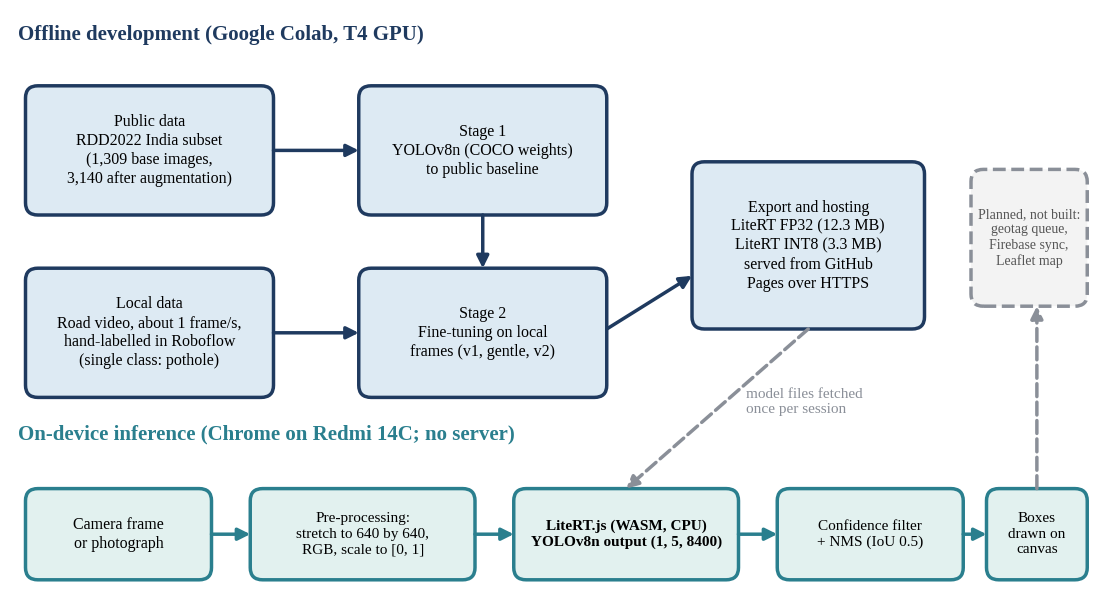

In [ ]:
# 12.3 Figure 1: system architecture (complete, self-contained)
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

if "SIZE_MB" not in globals():
    raise NameError("Run cell 12.1 (load your real results) first: it measures the model file sizes.")

NAVY, TEAL, GREY = "#1F3A5F", "#2A7F8E", "#8A8F98"
PALE_BLUE, PALE_TEAL, PALE_GREY = "#DDEAF3", "#E2F1EF", "#F3F3F3"
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"],
                     "mathtext.fontset": "stix"})
FIG_OUT = globals().get("FIG", "figures")
os.makedirs(FIG_OUT, exist_ok=True)

def box1(ax, x, y, w, h, text, fc, ec, lw=2.5, ls="-", bold=False, size=11.5, color="black"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.6",
                                fc=fc, ec=ec, lw=lw, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size,
            fontweight="bold" if bold else "normal", color=color, linespacing=1.25)

def arrow1(ax, p0, p1, color, lw=2.5, ls="-"):
    ax.annotate("", xy=p1, xytext=p0,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, ls=ls,
                                shrinkA=0, shrinkB=0, mutation_scale=18))

fig, ax = plt.subplots(figsize=(14, 7.6))
ax.set_xlim(0, 140); ax.set_ylim(-2, 75); ax.axis("off")

ax.text(1, 71, "Offline development (Google Colab, T4 GPU)", fontsize=15, fontweight="bold", color=NAVY)
box1(ax, 2, 48, 32, 17, "Public data\nRDD2022 India subset\n(1,309 base images,\n3,140 after augmentation)", PALE_BLUE, NAVY)
box1(ax, 2, 24, 32, 17, "Local data\nRoad video, about 1 frame/s,\nhand-labelled in Roboflow\n(single class: pothole)", PALE_BLUE, NAVY)
box1(ax, 45, 48, 32, 17, "Stage 1\nYOLOv8n (COCO weights)\nto public baseline", PALE_BLUE, NAVY)
box1(ax, 45, 24, 32, 17, "Stage 2\nFine-tuning on local\nframes (v1, gentle, v2)", PALE_BLUE, NAVY)
box1(ax, 88, 33, 30, 22, f"Export and hosting\nLiteRT FP32 ({SIZE_MB['FP32']:.1f} MB)\nLiteRT INT8 ({SIZE_MB['INT8']:.1f} MB)\nserved from GitHub\nPages over HTTPS", PALE_BLUE, NAVY)
box1(ax, 124, 36, 15, 18, "Planned, not built:\ngeotag queue,\nFirebase sync,\nLeaflet map", PALE_GREY, GREY, ls="--", size=10, color="#555555")
arrow1(ax, (34, 56.5), (45, 56.5), NAVY)
arrow1(ax, (34, 32.5), (45, 32.5), NAVY)
arrow1(ax, (61, 48), (61, 41), NAVY)
arrow1(ax, (77, 33), (88, 40), NAVY)

ax.text(1, 18.5, "On-device inference (Chrome on Redmi 14C; no server)", fontsize=15, fontweight="bold", color=TEAL)
y0, h0 = 0, 12
box1(ax, 2, y0, 24, h0, "Camera frame\nor photograph", PALE_TEAL, TEAL)
box1(ax, 31, y0, 29, h0, "Pre-processing:\nstretch to 640 by 640,\nRGB, scale to [0, 1]", PALE_TEAL, TEAL, size=11)
box1(ax, 65, y0, 29, h0, "LiteRT.js (WASM, CPU)\nYOLOv8n output (1, 5, 8400)", PALE_TEAL, TEAL, bold=True, size=11)
box1(ax, 99, y0, 24, h0, "Confidence filter\n+ NMS (IoU 0.5)", PALE_TEAL, TEAL, size=11)
box1(ax, 126, y0, 13, h0, "Boxes\ndrawn on\ncanvas", PALE_TEAL, TEAL, size=11)
for a, b in [(26, 31), (60, 65), (94, 99), (123, 126)]:
    arrow1(ax, (a, 6), (b, 6), TEAL)
arrow1(ax, (103, 33), (79.5, 12), GREY, ls="--")
ax.text(95, 22, "model files fetched\nonce per session", fontsize=11, color=GREY)
arrow1(ax, (132.5, 12), (132.5, 36), GREY, ls="--")

for ext in ("png", "pdf"):
    fig.savefig(f"{FIG_OUT}/fig1_architecture.{ext}", dpi=300, facecolor="white", bbox_inches="tight", pad_inches=0.08)
print("saved", f"{FIG_OUT}/fig1_architecture.png")
plt.show()

saved /content/drive/MyDrive/COEN872_pothole/figures/fig2_model_pipeline.png


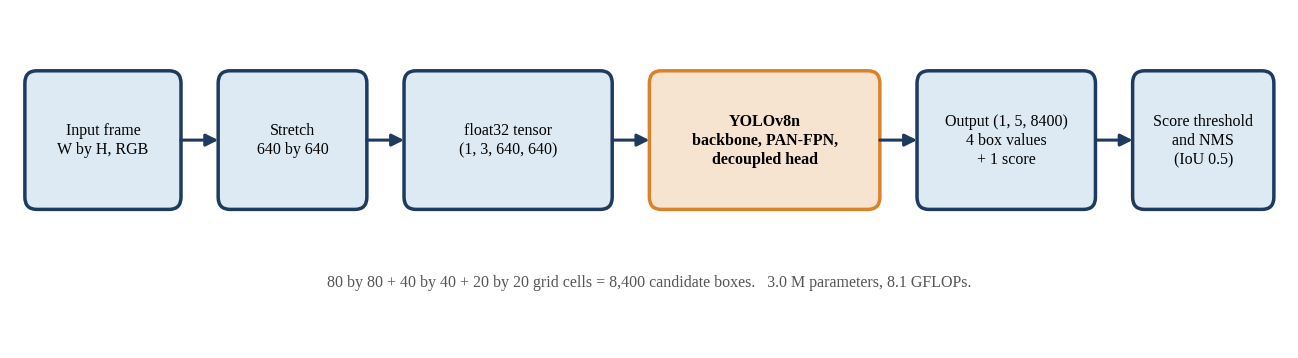

In [ ]:
# 12.4 Figure 2: model pipeline (complete, self-contained)
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

NAVY, ORANGE = "#1F3A5F", "#D9822B"
PALE_BLUE, PALE_ORANGE = "#DDEAF3", "#F7E4D0"
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"],
                     "mathtext.fontset": "stix"})
FIG_OUT = globals().get("FIG", "figures")
os.makedirs(FIG_OUT, exist_ok=True)

def box1(ax, x, y, w, h, text, fc, ec, lw=2.5, ls="-", bold=False, size=11.5, color="black"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.6",
                                fc=fc, ec=ec, lw=lw, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size,
            fontweight="bold" if bold else "normal", color=color, linespacing=1.25)

def arrow1(ax, p0, p1, color, lw=2.5, ls="-"):
    ax.annotate("", xy=p1, xytext=p0,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, ls=ls,
                                shrinkA=0, shrinkB=0, mutation_scale=18))

fig, ax = plt.subplots(figsize=(16.5, 4.4))
ax.set_xlim(-1, 171); ax.set_ylim(0, 44); ax.axis("off")
specs = [
    (1,   21, "Input frame\nW by H, RGB",                     PALE_BLUE,   NAVY,   False),
    (27,  20, "Stretch\n640 by 640",                         PALE_BLUE,   NAVY,   False),
    (52,  28, "float32 tensor\n(1, 3, 640, 640)",            PALE_BLUE,   NAVY,   False),
    (85,  31, "YOLOv8n\nbackbone, PAN-FPN,\ndecoupled head",  PALE_ORANGE, ORANGE, True),
    (121, 24, "Output (1, 5, 8400)\n4 box values\n+ 1 score", PALE_BLUE,   NAVY,   False),
    (150, 19, "Score threshold\nand NMS\n(IoU 0.5)",          PALE_BLUE,   NAVY,   False),
]
for x, w, t, fc, ec, b in specs:
    box1(ax, x, 18, w, 18, t, fc, ec, bold=b, size=11.5)
for p, q in [(22, 27), (47, 52), (80, 85), (116, 121), (145, 150)]:
    arrow1(ax, (p, 27), (q, 27), NAVY, lw=2.2)
ax.text(85, 8, "80 by 80 + 40 by 40 + 20 by 20 grid cells = 8,400 candidate boxes.   3.0 M parameters, 8.1 GFLOPs.",
        ha="center", fontsize=11.5, color="#555555")

for ext in ("png", "pdf"):
    fig.savefig(f"{FIG_OUT}/fig2_model_pipeline.{ext}", dpi=300, facecolor="white", bbox_inches="tight", pad_inches=0.08)
print("saved", f"{FIG_OUT}/fig2_model_pipeline.png")
plt.show()

In [ ]:
# 12.5 Metric definitions: precision, recall, F1 and IoU (complete, self-contained)
import os
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"],
                     "mathtext.fontset": "stix"})
FIG_OUT = globals().get("FIG", "figures")
os.makedirs(FIG_OUT, exist_ok=True)

fig = plt.figure(figsize=(12, 1.5))
fig.text(0.02, 0.5, r"$P=\frac{TP}{TP+FP}$", fontsize=22, va="center")
fig.text(0.28, 0.5, r"$R=\frac{TP}{TP+FN}$", fontsize=22, va="center")
fig.text(0.54, 0.5, r"$F_1=\frac{2PR}{P+R}$", fontsize=22, va="center")
fig.text(0.76, 0.5, r"$\mathrm{IoU}=\frac{|B_p\cap B_{gt}|}{|B_p\cup B_{gt}|}$", fontsize=22, va="center")

for ext in ("png", "pdf"):
    fig.savefig(f"{FIG_OUT}/fig_metric_equations.{ext}", dpi=300, facecolor="white", bbox_inches="tight", pad_inches=0.08)
print("saved", f"{FIG_OUT}/fig_metric_equations.png")
plt.show()

saved /content/drive/MyDrive/COEN872_pothole/figures/fig_metric_equations.png


<Figure size 1200x150 with 0 Axes>

saved /content/drive/MyDrive/COEN872_pothole/figures/fig3_public_vs_local.png
{'Public baseline': (0.29, 0.035), 'Fine-tuned v1': (0.042, 0.211), 'Gentle fine-tune': (0.178, 0.121), 'Fine-tuned v2': (0.062, 0.2)}


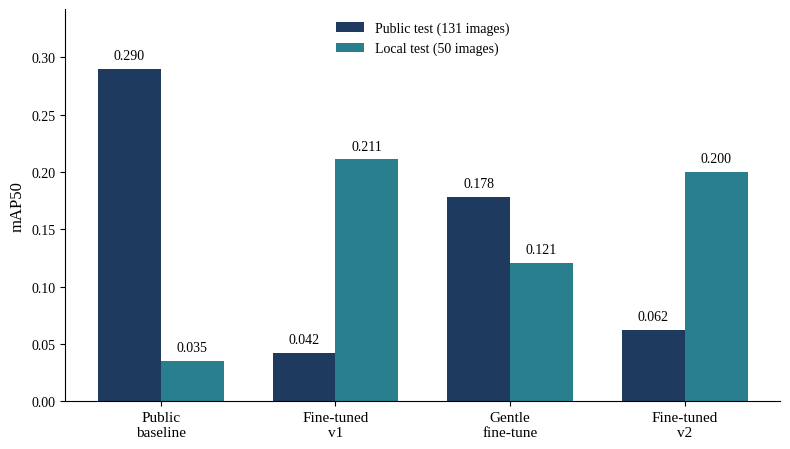

In [ ]:
# 12.6 Figure 3: mAP50 on the public test set versus the 50 local test images (PyTorch weights)
import os
import numpy as np
import matplotlib.pyplot as plt

for n in ("df_pt", "df_f", "df_g", "get", "FIG"):
    if n not in globals():
        raise NameError(f"Run cells 12.1 and 12.2 first ({n} is missing).")

def pt(cfg, test):
    m = df_pt[(df_pt["config"] == cfg) & (df_pt["test set"] == test)]
    if len(m) != 1:
        raise ValueError(f"Expected one row for {cfg} / {test}")
    return float(m["mAP50"].iloc[0])

models = ["Public\nbaseline", "Fine-tuned\nv1", "Gentle\nfine-tune", "Fine-tuned\nv2"]
pub = [pt("Public baseline", "public test"), pt("Fine-tuned v1", "public test"),
       get(df_f, "F", "public test", "mAP50"), get(df_g, "G", "public test", "mAP50")]
loc = [pt("Public baseline", "local test"), pt("Fine-tuned v1", "local test"),
       get(df_f, "F", "local test", "mAP50"), get(df_g, "G", "local test", "mAP50")]

NAVY, TEAL = "#1F3A5F", "#2A7F8E"
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"]})
x, w = np.arange(len(models)), 0.36
fig, ax = plt.subplots(figsize=(8, 4.6))
b1 = ax.bar(x - w/2, pub, w, color=NAVY, label="Public test (131 images)")
b2 = ax.bar(x + w/2, loc, w, color=TEAL, label="Local test (50 images)")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.006, f"{r.get_height():.3f}",
                ha="center", va="bottom", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(models, fontsize=11)
ax.set_ylabel("mAP50", fontsize=12)
ax.set_ylim(0, max(pub + loc) * 1.18)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=10, loc="upper center")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(f"{FIG}/fig3_public_vs_local.{ext}", dpi=300, facecolor="white", bbox_inches="tight")
print("saved", f"{FIG}/fig3_public_vs_local.png")
print(dict(zip([m.replace(chr(10), ' ') for m in models], zip(pub, loc))))
plt.show()

saved /content/drive/MyDrive/COEN872_pothole/figures/fig4_fp32_vs_int8.png


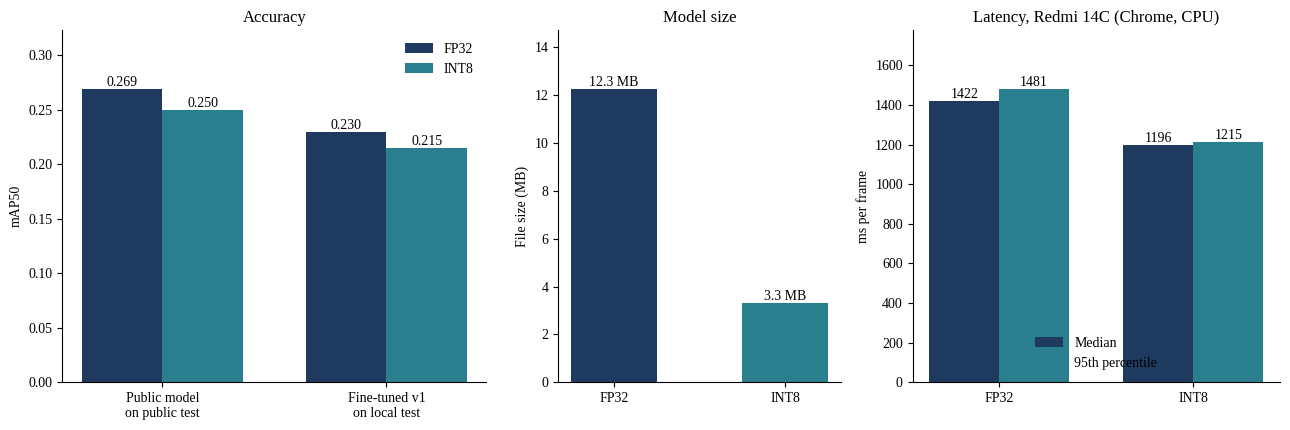

In [ ]:
# 12.7 Figure 4: FP32 versus INT8 exports: accuracy, file size and on-device latency
import numpy as np
import matplotlib.pyplot as plt

for n in ("df_ab", "df_cd", "get", "SIZE_MB", "LATENCY", "FIG"):
    if n not in globals():
        raise NameError(f"Run cell 12.1 first ({n} is missing).")

acc = {
    "Public model\non public test": (get(df_ab, "A", "public test", "mAP50"), get(df_ab, "B", "public test", "mAP50")),
    "Fine-tuned v1\non local test": (get(df_cd, "C", "local test", "mAP50"), get(df_cd, "D", "local test", "mAP50")),
}
NAVY, TEAL = "#1F3A5F", "#2A7F8E"
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"]})
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.5, 1, 1.3]})

def label(ax, bars, fmt):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height(), fmt.format(r.get_height()),
                ha="center", va="bottom", fontsize=10)

ax = axs[0]
x, w = np.arange(len(acc)), 0.36
v32 = [v[0] for v in acc.values()]; v8 = [v[1] for v in acc.values()]
label(ax, ax.bar(x - w/2, v32, w, color=NAVY, label="FP32"), "{:.3f}")
label(ax, ax.bar(x + w/2, v8, w, color=TEAL, label="INT8"), "{:.3f}")
ax.set_xticks(x); ax.set_xticklabels(list(acc.keys()), fontsize=10)
ax.set_ylabel("mAP50"); ax.set_title("Accuracy", fontsize=12)
ax.set_ylim(0, max(v32 + v8) * 1.2); ax.legend(frameon=False, fontsize=10)

ax = axs[1]
sizes = [SIZE_MB["FP32"], SIZE_MB["INT8"]]
label(ax, ax.bar(["FP32", "INT8"], sizes, 0.5, color=[NAVY, TEAL]), "{:.1f} MB")
ax.set_ylabel("File size (MB)"); ax.set_title("Model size", fontsize=12)
ax.set_ylim(0, max(sizes) * 1.2)

ax = axs[2]
med = [LATENCY["median"]["FP32"], LATENCY["median"]["INT8"]]
p95 = [LATENCY["p95"]["FP32"], LATENCY["p95"]["INT8"]]
x, w = np.arange(2), 0.36
label(ax, ax.bar(x - w/2, med, w, color=NAVY, label="Median"), "{:.0f}")
label(ax, ax.bar(x + w/2, p95, w, color=TEAL, label="95th percentile"), "{:.0f}")
ax.set_xticks(x); ax.set_xticklabels(["FP32", "INT8"])
ax.set_ylabel("ms per frame"); ax.set_title("Latency, Redmi 14C (Chrome, CPU)", fontsize=12)
ax.set_ylim(0, max(p95) * 1.2); ax.legend(frameon=False, fontsize=10, loc="lower center")

for a in axs:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(f"{FIG}/fig4_fp32_vs_int8.{ext}", dpi=300, facecolor="white", bbox_inches="tight")
print("saved", f"{FIG}/fig4_fp32_vs_int8.png")
plt.show()

Public baseline | epochs run: 50 | best validation mAP50: 0.35 | at epoch: 42
Fine-tuned v1 | epochs run: 50 | best validation mAP50: 0.381 | at epoch: 50
saved /content/drive/MyDrive/COEN872_pothole/figures/fig_training_curves.png


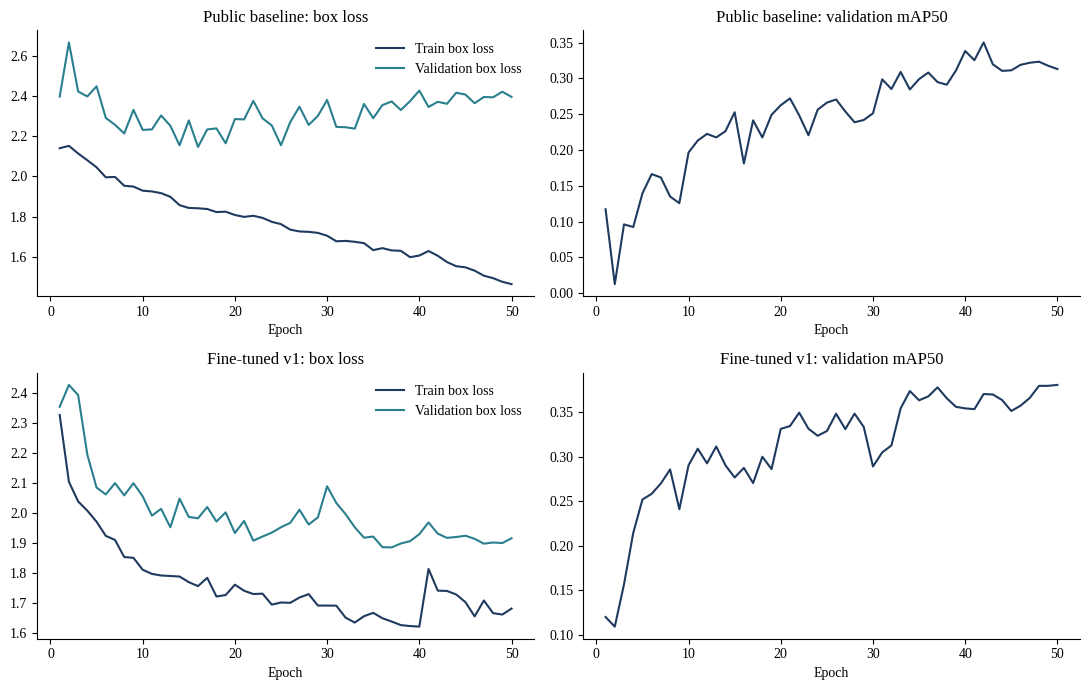

In [ ]:
# 12.8 Training curves from the results.csv files saved by Ultralytics
import os
import pandas as pd
import matplotlib.pyplot as plt

for n in ("OUT", "FIG"):
    if n not in globals():
        raise NameError("Run cell 12.1 first.")

runs = {"Public baseline": f"{OUT}/yolov8n_baseline/results.csv",
        "Fine-tuned v1": f"{OUT}/yolov8n_local_ft/results.csv"}
NAVY, TEAL = "#1F3A5F", "#2A7F8E"
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"]})
fig, axs = plt.subplots(len(runs), 2, figsize=(11, 7))
for r, (name, path) in enumerate(runs.items()):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing {path}. Files in run folder: {os.listdir(os.path.dirname(path))}")
    d = pd.read_csv(path)
    d.columns = [c.strip() for c in d.columns]
    ax = axs[r, 0]
    ax.plot(d["epoch"], d["train/box_loss"], color=NAVY, label="Train box loss")
    ax.plot(d["epoch"], d["val/box_loss"], color=TEAL, label="Validation box loss")
    ax.set_title(f"{name}: box loss", fontsize=12); ax.set_xlabel("Epoch"); ax.legend(frameon=False)
    ax = axs[r, 1]
    ax.plot(d["epoch"], d["metrics/mAP50(B)"], color=NAVY)
    ax.set_title(f"{name}: validation mAP50", fontsize=12); ax.set_xlabel("Epoch")
    best = d["metrics/mAP50(B)"].max()
    print(name, "| epochs run:", len(d), "| best validation mAP50:", round(best, 3),
          "| at epoch:", int(d.loc[d["metrics/mAP50(B)"].idxmax(), "epoch"]))
for a in axs.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(f"{FIG}/fig_training_curves.{ext}", dpi=300, facecolor="white", bbox_inches="tight")
print("saved", f"{FIG}/fig_training_curves.png")
plt.show()

test images found: 50 (expected 50)
saved /content/drive/MyDrive/COEN872_pothole/figures/fig_real_detections.png
images used: ['VID_20260927_134244_t0000000_jpg.rf.bdb9a389d97c60bae7eeece5734b89e7.jpg', 'VID_20260927_134244_t0039011_jpg.rf.afab280ddfd99a9f96d69a771c5e6fb1.jpg', 'VID_20260927_134550_t0039011_jpg.rf.c9b156335dcce79ec7767c9a065d64b2.jpg', 'VID_20260930_121446_t0030082_jpg.rf.f813456ad361b71edb7cf6c713999f6d.jpg', 'VID_20260930_121614_t0032008_jpg.rf.914bfdfed45720bd502cca290a34b756.jpg', 'VID_20260930_122043_t0036009_jpg.rf.7b0eb5de946dd9e122acfbee3b997381.jpg']


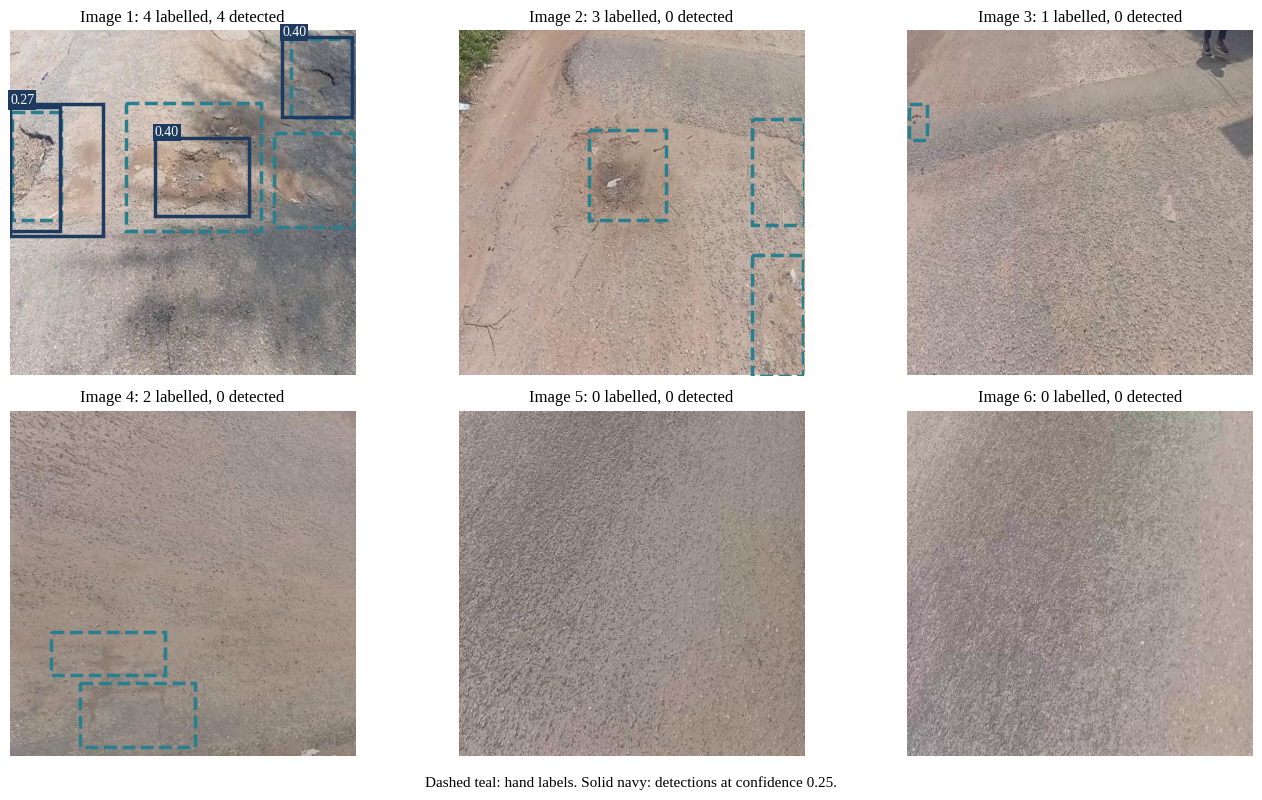

In [ ]:
# 12.9 Real detections of fine-tuned v1 on six local test images
# Picks are fixed and evenly spaced through the sorted test folder, so they are not chosen for looking good.
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

for n in ("OUT", "FIG"):
    if n not in globals():
        raise NameError("Run cell 12.1 first.")

IMG_DIR = "/content/local_test/test/images"
LBL_DIR = "/content/local_test/test/labels"
if not os.path.isdir(IMG_DIR):
    raise FileNotFoundError("Local test set not found. Run Section 11 step 1 first to download it.")

files = sorted(glob.glob(f"{IMG_DIR}/*.jpg") + glob.glob(f"{IMG_DIR}/*.png"))
print("test images found:", len(files), "(expected 50)")
picks = [files[i] for i in np.linspace(0, len(files) - 1, 6).astype(int)]
model = YOLO(f"{OUT}/yolov8n_local_ft/weights/best.pt")

NAVY, TEAL = "#1F3A5F", "#2A7F8E"
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"]})
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for k, (ax, p) in enumerate(zip(axs.ravel(), picks), 1):
    im = Image.open(p).convert("RGB"); W, H = im.size
    ax.imshow(im); ax.axis("off")
    lp = os.path.join(LBL_DIR, os.path.splitext(os.path.basename(p))[0] + ".txt")
    ngt = 0
    if os.path.exists(lp):
        for line in open(lp).read().strip().splitlines():
            if not line.strip():
                continue
            _, xc, yc, w, h = map(float, line.split()[:5]); ngt += 1
            ax.add_patch(Rectangle(((xc - w/2) * W, (yc - h/2) * H), w * W, h * H,
                                   fill=False, ec=TEAL, lw=2.5, ls="--"))
    res = model.predict(p, conf=0.25, imgsz=640, verbose=False)[0]
    for (x1, y1, x2, y2), c in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy()):
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=NAVY, lw=2.5))
        ax.text(x1, max(y1 - 4, 10), f"{c:.2f}", color="white", fontsize=10,
                bbox=dict(fc=NAVY, ec="none", pad=1.5))
    ax.set_title(f"Image {k}: {ngt} labelled, {len(res.boxes)} detected", fontsize=12)
fig.text(0.5, 0.01, "Dashed teal: hand labels. Solid navy: detections at confidence 0.25.",
         ha="center", fontsize=11)
fig.tight_layout(rect=(0, 0.03, 1, 1))
for ext in ("png", "pdf"):
    fig.savefig(f"{FIG}/fig_real_detections.{ext}", dpi=300, facecolor="white", bbox_inches="tight")
print("saved", f"{FIG}/fig_real_detections.png")
print("images used:", [os.path.basename(p) for p in picks])
plt.show()

In [ ]:
# 12.10 Zip the figures folder and download it
import os
import shutil

for n in ("FIG",):
    if n not in globals():
        raise NameError("Run cell 12.1 first.")

expected = [
    "fig1_architecture.png",
    "fig2_model_pipeline.png",
    "fig_metric_equations.png",
    "fig3_public_vs_local.png",
    "fig4_fp32_vs_int8.png",
    "fig_training_curves.png",
    "fig_real_detections.png",
]
present = sorted(os.listdir(FIG))
print("files in figures folder:")
for f in present:
    print("  ", f, f"({os.path.getsize(os.path.join(FIG, f)) / 1e3:.0f} KB)")
missing = [f for f in expected if f not in present]
print("\nmissing figures:", missing if missing else "none")

zip_base = "/content/COEN872_figures"
shutil.make_archive(zip_base, "zip", FIG)
print("\nzip created:", zip_base + ".zip", f"({os.path.getsize(zip_base + '.zip') / 1e6:.1f} MB)")

try:
    from google.colab import files
    files.download(zip_base + ".zip")
except Exception as e:
    print("Automatic download did not start:", e)
    print("Open the Files panel on the left, find COEN872_figures.zip and download it from there.")

files in figures folder:
   fig1_architecture.pdf (39 KB)
   fig1_architecture.png (446 KB)
   fig2_model_pipeline.pdf (28 KB)
   fig2_model_pipeline.png (171 KB)
   fig3_public_vs_local.pdf (15 KB)
   fig3_public_vs_local.png (95 KB)
   fig4_fp32_vs_int8.pdf (19 KB)
   fig4_fp32_vs_int8.png (171 KB)
   fig_metric_equations.pdf (12 KB)
   fig_metric_equations.png (37 KB)
   fig_real_detections.pdf (6416 KB)
   fig_real_detections.png (6927 KB)
   fig_training_curves.pdf (19 KB)
   fig_training_curves.png (391 KB)

missing figures: none

zip created: /content/COEN872_figures.zip (14.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>